<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Hacker News API](https://github.com/Query-farm/vgi-hackernews)

Front-page rankings, stories, comment threads and user profiles from the public Hacker News API.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-hackernews/blob/main/notebooks/03_an_id_window_is_not_a_time_window.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-hackernews/blob/main/notebooks/README.md)

## An item-ID window is not a time window

What kinds of records appear among recent Hacker News IDs, and how much clock time do those IDs span? Materialize 100 candidate IDs once, keep missing IDs visible, and vary only the local prefix. This is a finite acquisition, not a posting-rate estimate.

### Change one bounded view

`ID_WINDOW` accepts **25 or 100** IDs. Both runs read the same recorded 100-ID source; the parameter changes only the local selection. Default responses are recorded from the official API; live mode is explicit and never falls back. Edit, then **Restart Kernel → Run All**.

In [1]:
ID_WINDOW = 25  # Experiment: 100
DATA_MODE = "replay"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.41":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.41"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("hackernews")
import json  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
from IPython.display import display  # noqa: E402

from hackernews_example import Source, selection  # noqa: E402

theme()

recording = Source(DATA_MODE, "recent")
session = connect(globals())
con = session.connection

### Connect the released worker

The public **v0.3.0** release runs in its own `uvx` environment. Shared setup isolates saved SQL credentials and keeps the parent connection on UTC. The Hacker News API requires no key.

`DATA_MODE="replay"` uses complete, hash-verified official responses through the worker's documented `HN_BASE_URL` setting. Its loopback server rejects unrecorded requests; it never forwards or falls back to the network. `"live"` explicitly reads the official public API. Capture and hydration are sequential operations, not an atomic snapshot. Content belongs to its authors; outputs below use identifiers and aggregates.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hackernews' AS hn (
    TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-hackernews@v0.3.0 vgi-hackernews'
);

,Success


In [5]:
selection(ID_WINDOW, "ID_WINDOW", {25, 100})

### Compare two explicit anchors

`max_item` reads the current maximum ID. `recent_items(100)` obtains its own maximum when its scan starts, then attempts exactly 100 IDs descending from that anchor. In live mode these are separate reads and may differ. In replay the same recorded `maxitem` response fixes both. Missing item responses become absent rows, not fabricated zero-score items.

In [6]:
%%sql
CREATE TABLE maximum AS SELECT * FROM hn.main.max_item;
CREATE TABLE recent AS SELECT * FROM hn.main.recent_items(100);
CREATE TABLE scan_anchor AS SELECT max(id) AS id FROM recent;
CREATE TABLE candidate_ids AS
SELECT a.id-r.i AS id,r.i+1 AS id_position FROM scan_anchor a,range(100) r(i);
CREATE TABLE selected_ids AS
SELECT e.id,e.id_position,r.type,r.created_at,r.deleted,r.dead,
 r.id IS NOT NULL AS returned,r.author IS NOT NULL AS author_known
FROM candidate_ids e LEFT JOIN recent r USING(id) WHERE e.id_position<={{ID_WINDOW}};

,Count


The inferred scan anchor is the largest **returned** ID. It equals the true attempted anchor only if that newest item was available. The recorded response includes that newest item, and the replay checks below prove the exact 100-ID range. A live mismatch is reported rather than silently claiming the same request bounds.

In [7]:
%%sql anchor_check <<
SELECT m.id AS separately_read_maximum,a.id AS largest_returned_id,
 m.id=a.id AS anchors_match,(SELECT count(*) FROM recent) AS returned_rows,
 (SELECT min(id) FROM recent) AS lowest_returned_id
FROM maximum m CROSS JOIN scan_anchor a;

In [8]:
display(anchor_check)
assert len(anchor_check) == 1 and 0 < len(con.execute("SELECT * FROM recent").df()) <= 100
if DATA_MODE == "replay":
    expected = json.loads(recording.bodies["/v0/maxitem.json"])
    assert anchor_check.largest_returned_id.iloc[0] == expected
    assert set(recording.requests) == set(recording.bodies)
    assert len(recording.requests) == 102
AS_OF = recording.as_of()
source_label = f"{DATA_MODE.title()} official Hacker News API · acquired {AS_OF[:19]} UTC\nOne bounded 100-ID source; selected prefix {ID_WINDOW}; non-atomic acquisition"
prose(
    f"Separate maximum **{int(anchor_check.separately_read_maximum.iloc[0])}**; largest returned ID **{int(anchor_check.largest_returned_id.iloc[0])}**. The scan returned **{int(anchor_check.returned_rows.iloc[0])} rows**. Matching anchors in this acquisition do not make separate live reads atomic."
)

,separately_read_maximum,largest_returned_id,anchors_match,returned_rows,lowest_returned_id
0,50502385,50502385,True,100,50502286


Separate maximum **50502385**; largest returned ID **50502385**. The scan returned **100 rows**. Matching anchors in this acquisition do not make separate live reads atomic.

### Include unavailable IDs in the denominator

Build an explicit ID grid and left join the returned rows. A missing row is different from a returned row whose type, author or time is NULL. Do not discard either before computing the selected population. Story-only lists cannot describe this mixture of items.

In [9]:
%%sql mix <<
SELECT CASE WHEN NOT returned THEN 'Unavailable ID' ELSE coalesce(type,'Unknown type') END AS kind,
 count(*) AS ids,count(*) FILTER(WHERE returned AND created_at IS NULL) AS missing_time,
 count(*) FILTER(WHERE returned AND (deleted OR dead)) AS deleted_or_dead
FROM selected_ids GROUP BY kind ORDER BY ids DESC,kind;

In [10]:
%%sql time_span <<
SELECT count(*) AS selected_ids,count(*) FILTER(WHERE returned) AS returned_rows,
 count(created_at) AS timed_rows,min(created_at) AS earliest_utc,max(created_at) AS latest_utc,
 epoch(max(created_at)-min(created_at))/60.0 AS observed_span_minutes,
 (SELECT md5(string_agg(CAST(id AS VARCHAR)||':'||coalesce(type,'NULL')||':'||coalesce(CAST(created_at AS VARCHAR),'NULL'),',' ORDER BY id)) FROM recent) AS source_fingerprint
FROM selected_ids;

In [11]:
display(mix)
display(time_span)
assert mix.ids.sum() == ID_WINDOW and time_span.selected_ids.iloc[0] == ID_WINDOW
assert time_span.timed_rows.iloc[0] <= time_span.returned_rows.iloc[0] <= ID_WINDOW
r = time_span.iloc[0]
span = "unavailable" if pd.isna(r.observed_span_minutes) else f"{r.observed_span_minutes:.2f} minutes"
prose(
    f"The **{ID_WINDOW} selected IDs** contain **{int(r.returned_rows)} returned rows** and **{int(r.timed_rows)} known creation timestamps**, spanning **{span}**. This span is descriptive of this ID prefix; dividing the count by it would not establish a stable posting rate."
)

,kind,ids,missing_time,deleted_or_dead
0,comment,24,0,1
1,story,1,0,1


,selected_ids,returned_rows,timed_rows,earliest_utc,latest_utc,observed_span_minutes,source_fingerprint
0,25,25,25,2026-11-14 23:56:08+00:00,2026-11-15 00:00:43+00:00,4.583333,0ca86a01fc55b942172ecb55a82f1f0e


The **25 selected IDs** contain **25 returned rows** and **25 known creation timestamps**, spanning **4.58 minutes**. This span is descriptive of this ID prefix; dividing the count by it would not establish a stable posting rate.

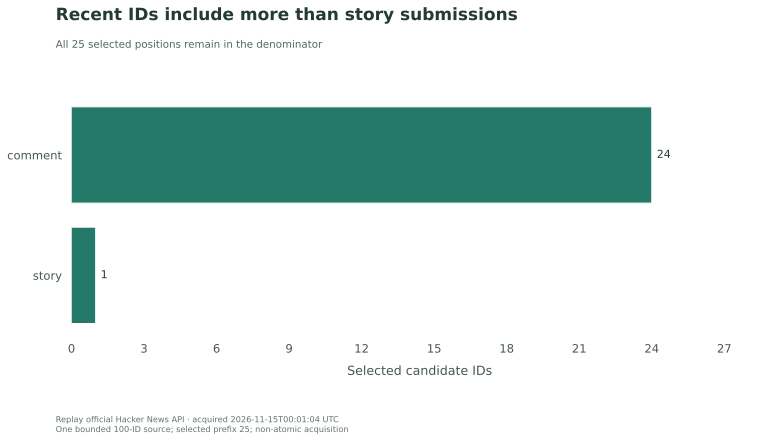

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(mix.kind, mix.ids, color="#257969")
ax.bar_label(bars, padding=5, fmt="%.0f")
ax.invert_yaxis()
ax.set(xlabel="Selected candidate IDs", xlim=(0, max(1, mix.ids.max()) * 1.2))
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
finish(
    fig,
    "Recent IDs include more than story submissions",
    f"All {ID_WINDOW} selected positions remain in the denominator",
    source_label,
    name=f"recent-mix-{ID_WINDOW}",
)

In [13]:
%%sql timeline <<
SELECT id_position,type,epoch(created_at-(SELECT min(created_at) FROM selected_ids))/60.0 AS minutes_since_earliest
FROM selected_ids WHERE created_at IS NOT NULL ORDER BY id_position;

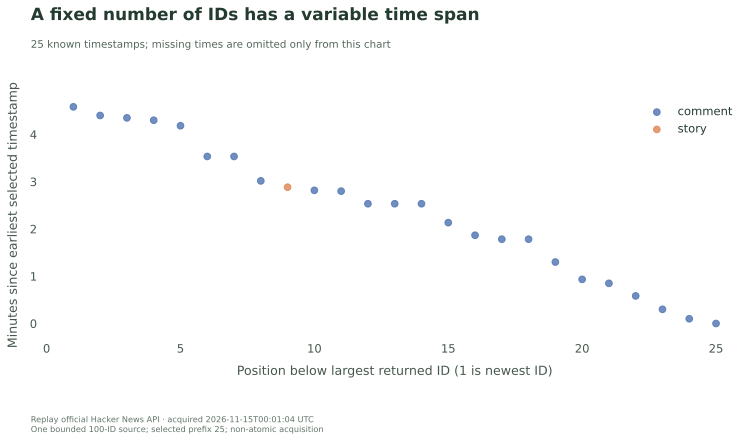

In [14]:
fig, ax = plt.subplots(figsize=(11, 6.5))
for kind, g in timeline.groupby("type", dropna=False):
    ax.scatter(
        g.id_position,
        g.minutes_since_earliest,
        s=46,
        alpha=0.8,
        label="Unknown type" if pd.isna(kind) else kind,
    )
ax.set(
    xlabel="Position below largest returned ID (1 is newest ID)",
    ylabel="Minutes since earliest selected timestamp",
    xlim=(0, ID_WINDOW + 1),
)
ax.legend(loc="upper right")
finish(
    fig,
    "A fixed number of IDs has a variable time span",
    f"{len(timeline)} known timestamps; missing times are omitted only from this chart",
    source_label,
    name=f"recent-time-{ID_WINDOW}",
)

### Experiment: widen the same recorded ID prefix

Change **ID_WINDOW from 25 to 100**. Compare type counts, unavailable IDs, known timestamps and observed time span. The source fingerprint and replay request audit must remain unchanged. A larger ID prefix can include more time, but this single capture does not estimate a general arrival rate or the entire site's content mix.

In [15]:
display(pd.DataFrame([recording.audit()]))

,mode,requests,distinct_paths,rejected,live_network_instrumented
0,replay,102,101,0,False


In [16]:
session.close()
recording.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-hackernews](https://github.com/Query-farm/vgi-hackernews)